# Part 2 — deterministic T4 baseline audit

Train exactly **Part-1-config EEGNet** and the **unchanged vanilla transformer**. No custom model is trained.

1. Upload `eeg_dl_exam_3hr` to Google Drive, including Part 2's visible `dataset.zip`.
2. Select **Runtime → Change runtime type → T4 GPU**.
3. Set `DRIVE_PROJECT` below, then run all cells.

Defaults: subjects 1–8 / 9–10, 40 epochs, seeds 0/1/2, effective batch 64, FP16 training, strict deterministic kernels. The first seed of each model is repeated and must reproduce exact weights, predictions and loss histories. Six scientific runs plus two verification runs.

The notebook copies data to the runtime's local disk and saves completed runs to Drive. See `COLAB.md` for protocol details and `BASELINE_AUDIT.md` for the architecture walkthrough. T4 runtime will be measured, not assumed.

In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
from pathlib import Path
import os, sys, shutil, subprocess
from datetime import datetime, timezone

# EDIT THIS PATH if you put the uploaded folder somewhere else.
DRIVE_PROJECT = Path('/content/drive/MyDrive/Basil AI Intern OA')
DRIVE_PART2 = DRIVE_PROJECT / 'part2_transformer'
if not (DRIVE_PART2 / 'colab_audit.py').is_file():
    raise FileNotFoundError(f'Set DRIVE_PROJECT to the folder containing part2_transformer. Looked in {DRIVE_PART2}')

# Use a fresh local working copy; do not copy .venv, old outputs or Part 1.
stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
LOCAL_PART2 = Path('/content') / f'basil_part2_{stamp}'
LOCAL_PART2.mkdir()
for pattern in ['*.py', '*.md', 'requirements*.txt']:
    for source in DRIVE_PART2.glob(pattern):
        shutil.copy2(source, LOCAL_PART2 / source.name)
if (DRIVE_PART2 / 'dataset.zip').is_file():
    shutil.copy2(DRIVE_PART2 / 'dataset.zip', LOCAL_PART2 / 'dataset.zip')
    print('Copied dataset.zip. Checksums will be verified before training.')
elif (DRIVE_PART2 / '.cache/mne').is_dir():
    shutil.copytree(DRIVE_PART2 / '.cache/mne', LOCAL_PART2 / '.cache/mne')
else:
    print('No bundled recordings found; prepare_data.py will download them from PhysioNet.')

os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
os.environ['PYTHONDONTWRITEBYTECODE'] = '1'
DRIVE_OUTPUTS = DRIVE_PART2 / 'artifacts/colab_gpu'
DRIVE_OUTPUTS.mkdir(parents=True, exist_ok=True)
print('Local work:', LOCAL_PART2)
print('Drive results:', DRIVE_OUTPUTS)


Copied dataset.zip. Checksums will be verified before training.
Local work: /content/basil_part2_20261101T083358249641Z
Drive results: /content/drive/MyDrive/Basil AI Intern OA/part2_transformer/artifacts/colab_gpu


## Dependencies and GPU
Keep Colab's preinstalled CUDA-enabled PyTorch. Only install the scientific dependencies; the repository's laptop `.venv` is not used.

In [3]:
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', str(LOCAL_PART2 / 'requirements-colab.txt')], check=True)
import torch
if not torch.cuda.is_available():
    raise RuntimeError('Select Runtime > Change runtime type > T4 GPU, then reconnect and run again.')
print('GPU:', torch.cuda.get_device_name(0))
print('PyTorch:', torch.__version__, 'CUDA:', torch.version.cuda)
print('Capability:', torch.cuda.get_device_capability(0))
subprocess.run(['nvidia-smi'], check=True)


GPU: Tesla T4
PyTorch: 2.11.0+cu130 CUDA: 13.0
Capability: (7, 5)


CompletedProcess(args=['nvidia-smi'], returncode=0)

## Prepare and verify data
Extract the bundled recordings locally, check all 30 SHA-256 hashes against MNE's registry, filter/epoch, and verify the subject split and shapes. The loader preserves the starter's preprocessing.

In [4]:
subprocess.run([sys.executable, '-B', '-u', 'prepare_data.py'], cwd=LOCAL_PART2, check=True)
import json
print(json.dumps(json.loads((LOCAL_PART2 / 'artifacts/data_summary.json').read_text()), indent=2))


{
  "train_shape": [
    360,
    64,
    481
  ],
  "test_shape": [
    90,
    64,
    481
  ],
  "train_class_counts": [
    178,
    182
  ],
  "test_class_counts": [
    46,
    44
  ],
  "per_subject_trials": {
    "1": 45,
    "2": 45,
    "3": 45,
    "4": 45,
    "5": 45,
    "6": 45,
    "7": 45,
    "8": 45,
    "9": 45,
    "10": 45
  },
  "array_bytes": 55411200,
  "normalized_train_channel_std_range": [
    0.8860835433006287,
    0.9522490501403809
  ],
  "normalization_note": "Starter adds 1e-6 to std in volts, so channel std is below one; preserved for this audit.",
  "raw_bytes": 77040000,
  "seconds": 8.875296384999956
}


## Train and audit
Settings below define the experiment **before** training. EEGNet uses full batches of 64 to retain its batch-normalization behavior; the transformer accumulates 16-trial microbatches into the same effective batch size. Both use the prespecified final epoch and FP32 final evaluation.

Strict determinism stays enabled. The first seed for each model is independently repeated and checked exactly. Repeat runs are excluded from the accuracy summaries. Results are backed up to Drive after each completed seed. No test-accuracy checkpoint selection or hyperparameter search is performed.

In [9]:
EPOCHS = 40
SEEDS = [0, 1, 2, 3, 4]
EFFECTIVE_BATCH = 64
TRANSFORMER_MICROBATCH = 16
PRECISION = 'fp16'  # T4: mixed precision with gradient scaling
VERIFY_REPEATS = True

command = [sys.executable, '-B', '-u', 'colab_audit.py',
           '--device', 'cuda', '--precision', PRECISION,
           '--epochs', str(EPOCHS), '--seeds', *map(str, SEEDS),
           '--batch', str(EFFECTIVE_BATCH), '--microbatch', str(TRANSFORMER_MICROBATCH),
           '--strict-determinism', '--sync-dir', str(DRIVE_OUTPUTS)]
if not VERIFY_REPEATS:
    command += ['--no-verify-repeat']

# Stream progress and keep a persistent launcher log.
import signal
log_path = LOCAL_PART2 / 'artifacts/colab_launcher.log'
process = None
try:
    with log_path.open('w') as logfile:
        process = subprocess.Popen(command, cwd=LOCAL_PART2, stdout=subprocess.PIPE,
                                   stderr=subprocess.STDOUT, text=True, bufsize=1)
        for line in process.stdout:
            print(line, end='', flush=True)
            logfile.write(line)
            logfile.flush()
        returncode = process.wait()
    if returncode != 0:
        raise RuntimeError(f'Audit failed with exit code {returncode}. Read the log above and the saved metadata.')
except KeyboardInterrupt:
    if process is not None and process.poll() is None:
        process.send_signal(signal.SIGINT)
        try:
            process.wait(timeout=60)
        except subprocess.TimeoutExpired:
            process.terminate()
    raise
finally:
    if log_path.exists():
        shutil.copy2(log_path, DRIVE_OUTPUTS / f'launcher_{stamp}.log')


Output: /content/basil_part2_20261101T083358249641Z/artifacts/colab_20261101T085031308395Z
Device: Tesla T4; precision: fp16
eegnet_part1_config seed=0 epoch=1/40 loss=0.7274 train=0.456 time=1.003s
eegnet_part1_config seed=0 epoch=2/40 loss=0.7061 train=0.528 time=0.171s
eegnet_part1_config seed=0 epoch=3/40 loss=0.7023 train=0.497 time=0.174s
eegnet_part1_config seed=0 epoch=4/40 loss=0.7040 train=0.517 time=0.174s
eegnet_part1_config seed=0 epoch=5/40 loss=0.6746 train=0.572 time=0.173s
eegnet_part1_config seed=0 epoch=6/40 loss=0.6936 train=0.517 time=0.174s
eegnet_part1_config seed=0 epoch=7/40 loss=0.6804 train=0.547 time=0.175s
eegnet_part1_config seed=0 epoch=8/40 loss=0.6792 train=0.594 time=0.173s
eegnet_part1_config seed=0 epoch=9/40 loss=0.6753 train=0.606 time=0.174s
eegnet_part1_config seed=0 epoch=10/40 loss=0.6839 train=0.572 time=0.175s
eegnet_part1_config seed=0 epoch=11/40 loss=0.6804 train=0.553 time=0.173s
eegnet_part1_config seed=0 epoch=12/40 loss=0.6588 train=0.

## Read and export the audit
The report separates training time from test inference, shows every seed and subject, explains both architectures, and records the exact reproducibility checks. Exact repeats apply to this hardware/software stack; future Colab versions can change results.

# Part 2 GPU baseline audit

Hardware: Tesla T4. Training: fp16; final evaluation: FP32.

Budget: 40 epochs; seeds [0, 1, 2]; effective batch 64; transformer microbatch 16. EEGNet uses full effective batches to preserve BN statistics. Both models use AdamW, lr 0.001, weight decay 0.001.

## Experiment and data integrity

Exactly two models: EEGNet with Part 1's F1=8, D=2, F2=16, temporal kernel 80 and dropout 0.5; unchanged VanillaEEGTransformer with d=64, four heads, three layers and dropout 0.3.

Real experiment: EEGBCI subjects 1–8 for training (360 trials), subjects 9–10 for test (90 trials). Imagined both fists versus both feet; runs 6, 10, 14; 64 channels, 160 Hz, 481 samples per trial. 7–30 Hz filtering and training-only channel scaling. Raw data checksums are checked before training.

The Part 1 architecture is freshly trained on Part 2 preprocessing. This is not a reproduction of the Part 1 score or a reuse of its checkpoint. This audit does not train the custom model.

The final epoch is chosen before training; test scores never select checkpoints. There is no validation-based hyperparameter search. Data preprocessing fits training subjects only.

## Measured results

| Model | Params | Test best | Test worst | Test mean ± seed SD | Mean train accuracy | Mean training | Mean test inference |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| eegnet_part1_config | 2,738 | 60.00% | 54.44% | 57.04% ± 2.28 pp | 83.15% | 7.86 s | 0.0081 s |
| vanilla_transformer | 135,746 | 54.44% | 44.44% | 50.74% ± 4.48 pp | 99.07% | 28.46 s | 0.0431 s |

Inference time covers the complete test set, including probability transfer to CPU. It is measured once after training, not a repeated latency benchmark. GPU operations are synchronized for timing.

| Model | Seed | Train | Test | Balanced test | Subject 9 | Subject 10 | Peak allocated GPU MiB | Skipped AMP steps |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| eegnet_part1_config | 0 | 84.72% | 60.00% | 60.38% | 51.11% | 68.89% | 213.0 | 0 |
| eegnet_part1_config | 1 | 82.50% | 54.44% | 54.79% | 55.56% | 53.33% | 213.0 | 0 |
| eegnet_part1_config | 2 | 82.22% | 56.67% | 57.46% | 51.11% | 62.22% | 213.0 | 0 |
| vanilla_transformer | 0 | 99.44% | 54.44% | 54.99% | 55.56% | 53.33% | 649.5 | 0 |
| vanilla_transformer | 1 | 98.06% | 44.44% | 44.76% | 42.22% | 46.67% | 649.5 | 0 |
| vanilla_transformer | 2 | 99.72% | 53.33% | 53.75% | 51.11% | 55.56% | 649.5 | 0 |

Peak allocated memory includes resident data, model, optimizer and temporary tensors; it excludes CUDA allocations outside PyTorch's allocator. AMP may skip an update when gradients overflow; all skipped updates are counted.

## What the models compute

EEGNet: shared temporal filtering → frequency-specific full-scalp spatial filtering → separable temporal filtering → pooled features → linear classifier. Shapes excluding batch: 64×481 → 8×64×482 → 16×1×120 → 16×1×15 → 2 logits. It has 2,738 trainable parameters.

Vanilla: each 64-electrode instantaneous sample becomes one 64-dimensional token. Add CLS and learned temporal positions, then three standard encoder layers and a CLS classifier. It has 135,746 parameters, 482 tokens including CLS and 232,324 attention entries per head per layer. Head dimension is 16, so scaled attention divides QK dot products by 4. It attends across time; electrode identity enters through fixed slots in the projection, without explicit electrode geometry.

The transformer is about 50 times larger than this EEGNet. Differences cannot be attributed solely to attention. Strict mode selects deterministic math SDPA and does not assume T4 supports FlashAttention. AMP and microbatching are execution choices, not a new inductive bias.

Transformer microbatching preserves effective batch size and sample-weighted gradients, including short final batches. EEGNet trains with full effective batches so BN statistics are preserved. Dropout draws and floating-point reductions differ between GPU and CPU; this is not claimed bitwise equivalent to the CPU run.

## Reading the outcome

Compare the train/test gap, seed spread, predicted-class counts and subject-specific results together. A large training/test gap is compatible with overfitting; low training accuracy also permits optimization difficulty. This report does not declare a physiological mechanism from accuracy alone.

The real test majority-class reference is 46/90 = 51.11%; constant predictions have balanced accuracy 50%. One real test trial is 1.11 percentage points. Repeated seeds share the same two people: their SD is optimization variability, not a confidence interval over future subjects. Summed confusion matrices repeat the same test trials and do not increase the independent sample size.

Both-fists versus both-feet is bilateral. A left/right-only spatial prior misses this contrast. The cue/eye-position confound from Part 1 is not proven absent by filtering or cross-subject evaluation. No attention map, source localization or physiological explanation is inferred from these metrics.

## Artifacts

- `audit_dashboard.png`: loss curves, seed scores, subject scores, confusion matrices and runtime.
- `metadata.json`: architecture traces, source hashes, packages, GPU, precision and protocol.
- `results.jsonl`, `summary.json`: machine-readable per-seed and aggregate results.
- Per-seed history JSON and prediction CSV files; final checkpoints under `checkpoints/`.
- Dataset manifest and data summary, including SHA-256 checksums for all 30 recordings.

Reproducibility: strict deterministic algorithms enabled by default, seeded Python/NumPy/PyTorch, cuDNN benchmark and TF32 disabled, deterministic cuBLAS configured before torch import. Exact reproducibility applies to the same GPU and software stack, not arbitrary devices or releases.

## Actual reproducibility checks

The first seed for each model is repeated independently by default. Repeats do not enter seed averages.

- eegnet_part1_config, seed 0: weights exact=True, predictions exact=True, losses exact=True; additional training 7.08 s.
- vanilla_transformer, seed 0: weights exact=True, predictions exact=True, losses exact=True; additional training 27.96 s.

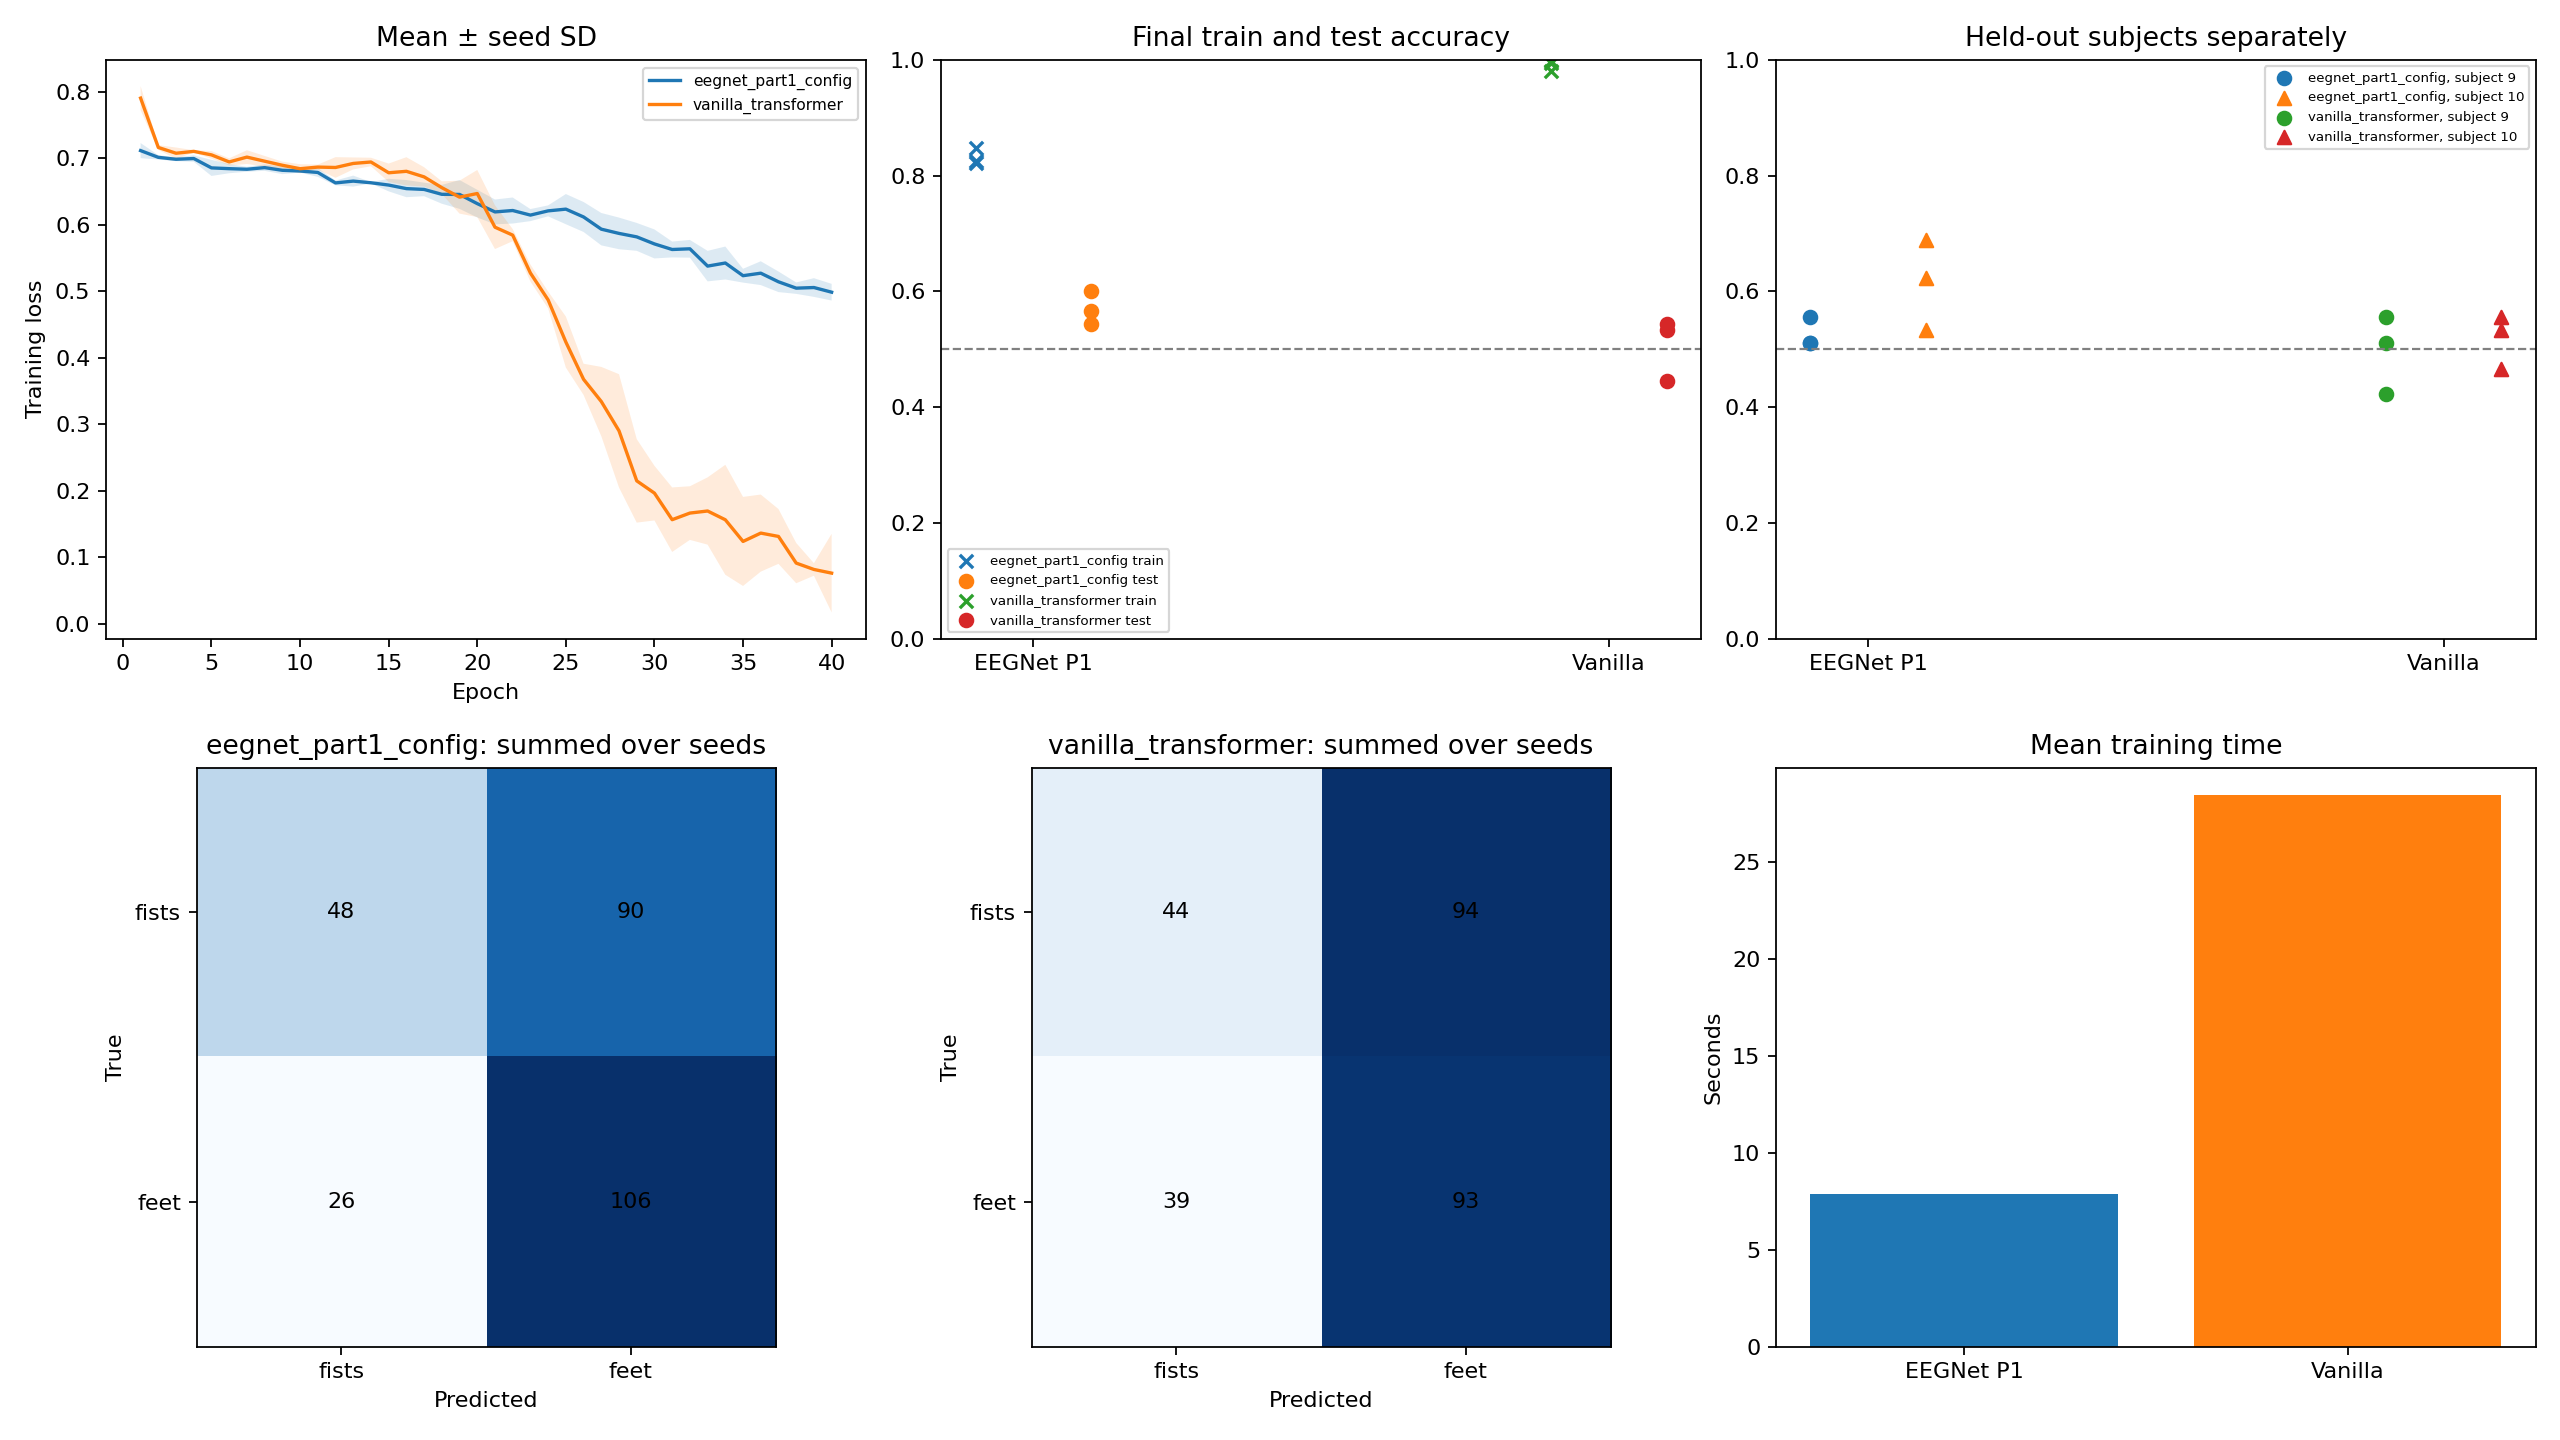

Detailed run folder: /content/drive/MyDrive/Basil AI Intern OA/part2_transformer/artifacts/colab_gpu/colab_20261101T083535270691Z
Export ZIP: /content/drive/MyDrive/Basil AI Intern OA/part2_transformer/artifacts/colab_gpu/colab_20261101T083535270691Z.zip


In [6]:
from IPython.display import display, Markdown, Image
runs = sorted((LOCAL_PART2 / 'artifacts').glob('colab_*'))
completed = [p for p in runs if p.is_dir() and (p / 'metadata.json').is_file()
             and json.loads((p / 'metadata.json').read_text()).get('status') == 'complete']
if not completed:
    raise RuntimeError('No completed audit. Check the training cell and its saved log.')
RUN_DIR = completed[-1]
display(Markdown((RUN_DIR / 'AUDIT_REPORT.md').read_text()))
display(Image(filename=str(RUN_DIR / 'audit_dashboard.png')))

archive = Path(shutil.make_archive(str(LOCAL_PART2 / RUN_DIR.name), 'zip', root_dir=RUN_DIR))
DRIVE_EXPORT = DRIVE_OUTPUTS / archive.name
shutil.copy2(archive, DRIVE_EXPORT)
print('Detailed run folder:', DRIVE_OUTPUTS / RUN_DIR.name)
print('Export ZIP:', DRIVE_EXPORT)


Optional: download the export ZIP to your laptop after training.

In [8]:
DOWNLOAD_TO_LAPTOP = True
if DOWNLOAD_TO_LAPTOP:
    from google.colab import files
    files.download(str(archive))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>